In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%config InlineBackend.figure_format = 'svg'

C:\Users\abdoa\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
df = pd.read_csv("house-prices-dataset/train.csv")
df.head(20)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


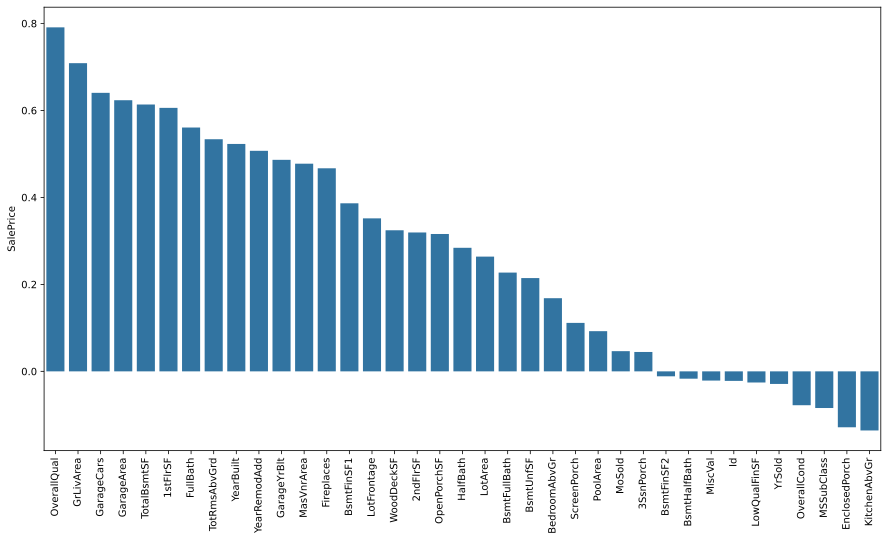

In [3]:
corr = df.corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values(ascending=False)

plt.figure(figsize=(15, 8))
sns.barplot(data=corr)
plt.xticks(rotation=90)
plt.show()

In [4]:
string_df = df.select_dtypes(include=["object", "string"])
string_df.columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='str')

In [5]:
df.LandContour.unique()

<ArrowStringArray>
['Lvl', 'Bnk', 'Low', 'HLS']
Length: 4, dtype: str

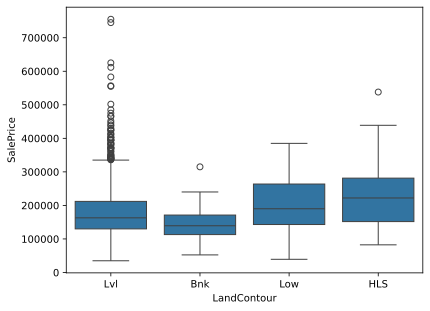

In [6]:
sns.boxplot(x="LandContour", y="SalePrice", data=df)
plt.show()

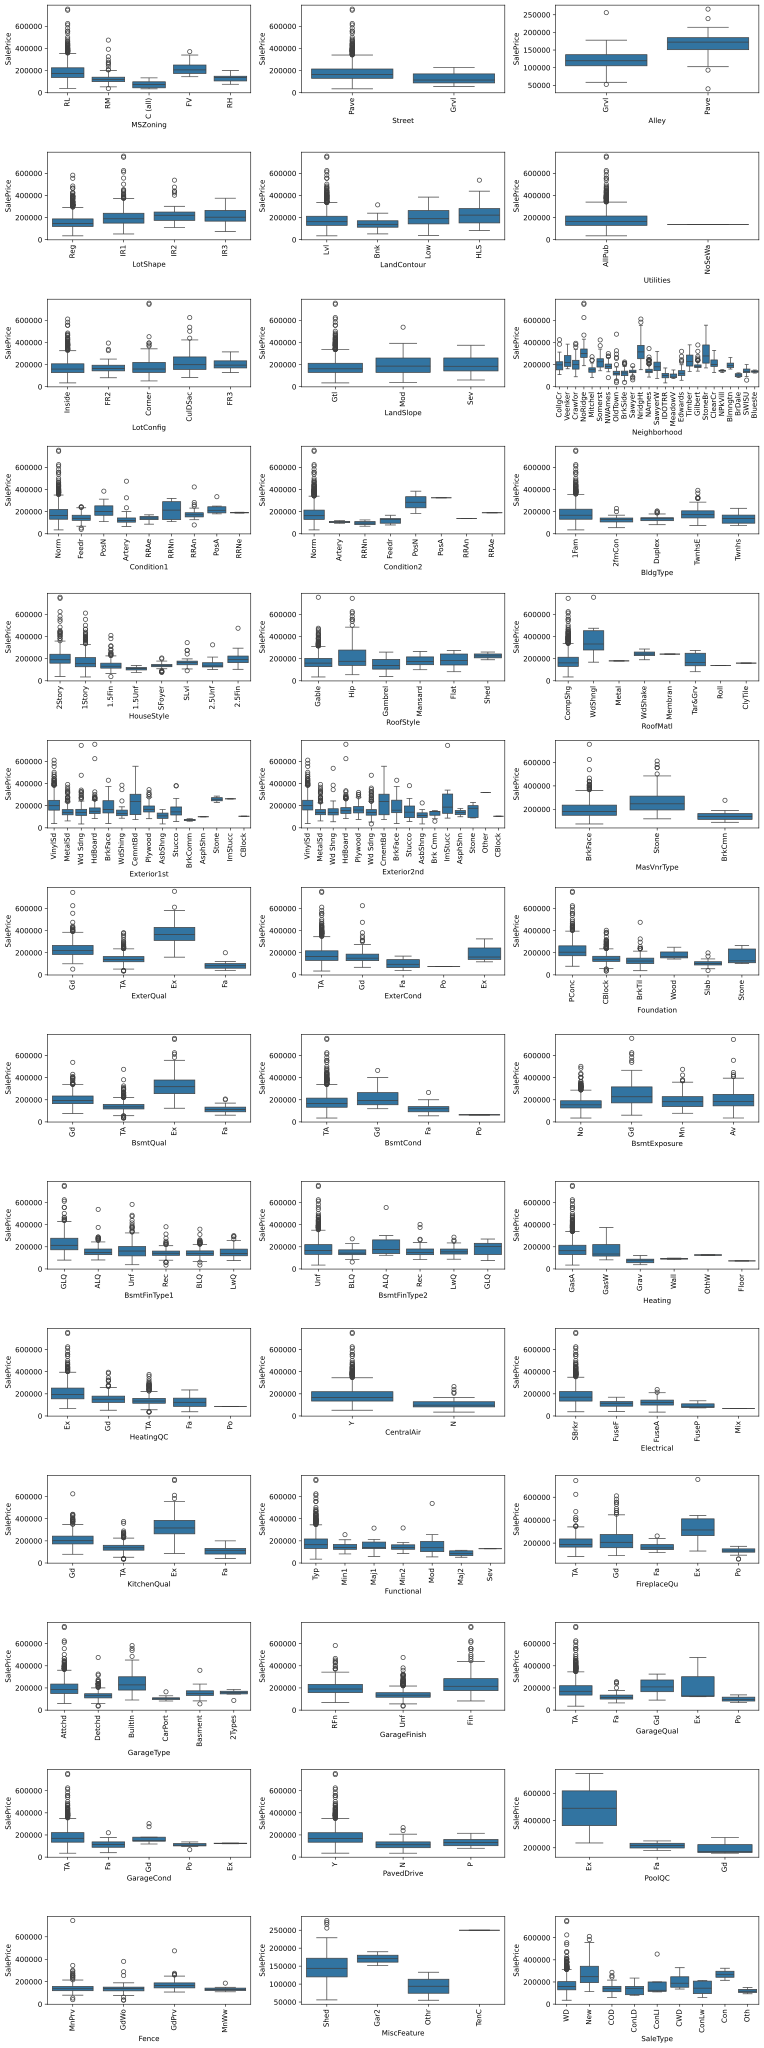

In [7]:
columns = string_df.columns.to_list()
fig, axes = plt.subplots(14, 3, figsize=(15, 40))
axes_flat = axes.flat
for column, ax in zip(columns, axes_flat):
    sns.boxplot(x=column, y="SalePrice", ax=ax, data=df)
    ax.tick_params(axis='x', rotation=90)
for ax in axes_flat[len(columns):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [8]:
string_df.columns.tolist()

['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

In [9]:
cols = [
    "Neighborhood",
    "Condition1",
    "Condition2",
    "HouseStyle",
    "RoofMatl",
    "SaleType",
    "SaleCondition",
    "ExterQual",
    "BsmtQual",
    "FireplaceQu",
    "KitchenQual",
    "Fireplaces",
    "OverallQual",
    "GarageYrBlt",
    "MasVnrArea",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "YearBuilt",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "SalePrice"
]

In [10]:
cleaned_df = df[cols]
cleaned_df

,Neighborhood,Condition1,Condition2,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,FireplaceQu,...,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,SalePrice
0,CollgCr,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,NaN,...,1710,2,548,856,2003,2,8,2003,2003,208500
1,Veenker,Feedr,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,...,1262,2,460,1262,1976,2,6,1976,1976,181500
2,CollgCr,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,TA,...,1786,2,608,920,2001,2,6,2001,2002,223500
3,Crawfor,Norm,Norm,2Story,CompShg,WD,Abnorml,TA,TA,Gd,...,1717,3,642,756,1915,1,7,1915,1970,140000
4,NoRidge,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,TA,...,2198,3,836,1145,2000,2,9,2000,2000,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,Gilbert,Norm,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,...,1647,2,460,953,1999,2,7,1999,2000,175000
1456,NWAmes,Norm,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,...,2073,2,500,1542,1978,2,7,1978,1988,210000
1457,Crawfor,Norm,Norm,2Story,CompShg,WD,Normal,Ex,TA,Gd,...,2340,1,252,1152,1941,2,9,1941,2006,266500
1458,NAmes,Norm,Norm,1Story,CompShg,WD,Normal,TA,TA,NaN,...,1078,1,240,1078,1950,1,5,1950,1996,142125


In [11]:
cleaned_df.drop("FireplaceQu", axis=1, inplace=True)

In [12]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Neighborhood   1460 non-null   str    
 1   Condition1     1460 non-null   str    
 2   Condition2     1460 non-null   str    
 3   HouseStyle     1460 non-null   str    
 4   RoofMatl       1460 non-null   str    
 5   SaleType       1460 non-null   str    
 6   SaleCondition  1460 non-null   str    
 7   ExterQual      1460 non-null   str    
 8   BsmtQual       1423 non-null   str    
 9   KitchenQual    1460 non-null   str    
 10  Fireplaces     1460 non-null   int64  
 11  OverallQual    1460 non-null   int64  
 12  GarageYrBlt    1379 non-null   float64
 13  MasVnrArea     1452 non-null   float64
 14  GrLivArea      1460 non-null   int64  
 15  GarageCars     1460 non-null   int64  
 16  GarageArea     1460 non-null   int64  
 17  TotalBsmtSF    1460 non-null   int64  
 18  YearBuilt      1460

In [13]:
df.loc[(df["GarageYrBlt"].isna()) & (df["GarageFinish"].isna()), ["GarageYrBlt", "GarageFinish"]]

,GarageYrBlt,GarageFinish
39,NaN,NaN
48,NaN,NaN
78,NaN,NaN
88,NaN,NaN
89,NaN,NaN
...,...,...
1349,NaN,NaN
1407,NaN,NaN
1449,NaN,NaN
1450,NaN,NaN


In [14]:
cleaned_df.fillna({"GarageYrBlt": cleaned_df["YearRemodAdd"]}, inplace=True)

,Neighborhood,Condition1,Condition2,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,KitchenQual,...,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,SalePrice
0,CollgCr,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,...,1710,2,548,856,2003,2,8,2003,2003,208500
1,Veenker,Feedr,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,...,1262,2,460,1262,1976,2,6,1976,1976,181500
2,CollgCr,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,...,1786,2,608,920,2001,2,6,2001,2002,223500
3,Crawfor,Norm,Norm,2Story,CompShg,WD,Abnorml,TA,TA,Gd,...,1717,3,642,756,1915,1,7,1915,1970,140000
4,NoRidge,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,...,2198,3,836,1145,2000,2,9,2000,2000,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,Gilbert,Norm,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,...,1647,2,460,953,1999,2,7,1999,2000,175000
1456,NWAmes,Norm,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,...,2073,2,500,1542,1978,2,7,1978,1988,210000
1457,Crawfor,Norm,Norm,2Story,CompShg,WD,Normal,Ex,TA,Gd,...,2340,1,252,1152,1941,2,9,1941,2006,266500
1458,NAmes,Norm,Norm,1Story,CompShg,WD,Normal,TA,TA,Gd,...,1078,1,240,1078,1950,1,5,1950,1996,142125


In [15]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [16]:
cleaned_df.BsmtQual.unique()

<ArrowStringArray>
['Gd', 'TA', 'Ex', nan, 'Fa']
Length: 5, dtype: str

In [17]:
cleaned_df.fillna({"BsmtQual": "TA"}, inplace=True)

,Neighborhood,Condition1,Condition2,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,KitchenQual,...,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,SalePrice
0,CollgCr,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,...,1710,2,548,856,2003,2,8,2003,2003,208500
1,Veenker,Feedr,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,...,1262,2,460,1262,1976,2,6,1976,1976,181500
2,CollgCr,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,...,1786,2,608,920,2001,2,6,2001,2002,223500
3,Crawfor,Norm,Norm,2Story,CompShg,WD,Abnorml,TA,TA,Gd,...,1717,3,642,756,1915,1,7,1915,1970,140000
4,NoRidge,Norm,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,...,2198,3,836,1145,2000,2,9,2000,2000,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,Gilbert,Norm,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,...,1647,2,460,953,1999,2,7,1999,2000,175000
1456,NWAmes,Norm,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,...,2073,2,500,1542,1978,2,7,1978,1988,210000
1457,Crawfor,Norm,Norm,2Story,CompShg,WD,Normal,Ex,TA,Gd,...,2340,1,252,1152,1941,2,9,1941,2006,266500
1458,NAmes,Norm,Norm,1Story,CompShg,WD,Normal,TA,TA,Gd,...,1078,1,240,1078,1950,1,5,1950,1996,142125


In [18]:
cleaned_df.isna().sum()

Neighborhood     0
Condition1       0
Condition2       0
HouseStyle       0
RoofMatl         0
SaleType         0
SaleCondition    0
ExterQual        0
BsmtQual         0
KitchenQual      0
Fireplaces       0
OverallQual      0
GarageYrBlt      0
MasVnrArea       8
GrLivArea        0
GarageCars       0
GarageArea       0
TotalBsmtSF      0
YearBuilt        0
FullBath         0
TotRmsAbvGrd     0
YearBuilt        0
YearRemodAdd     0
SalePrice        0
dtype: int64

In [19]:
cleaned_df.dropna(inplace=True)

In [20]:
cleaned_df.isna().sum()

Neighborhood     0
Condition1       0
Condition2       0
HouseStyle       0
RoofMatl         0
SaleType         0
SaleCondition    0
ExterQual        0
BsmtQual         0
KitchenQual      0
Fireplaces       0
OverallQual      0
GarageYrBlt      0
MasVnrArea       0
GrLivArea        0
GarageCars       0
GarageArea       0
TotalBsmtSF      0
YearBuilt        0
FullBath         0
TotRmsAbvGrd     0
YearBuilt        0
YearRemodAdd     0
SalePrice        0
dtype: int64

In [21]:
cleaned_df["Condition1"].unique()

<ArrowStringArray>
['Norm', 'Feedr', 'PosN', 'Artery', 'RRAe', 'RRNn', 'RRAn', 'PosA', 'RRNe']
Length: 9, dtype: str

In [22]:
cleaned_df["Condition2"].unique()

<ArrowStringArray>
['Norm', 'Artery', 'RRNn', 'Feedr', 'PosN', 'PosA', 'RRAn', 'RRAe']
Length: 8, dtype: str

In [23]:
(cleaned_df["Condition1"] == cleaned_df["Condition2"]).sum()

1257

In [24]:
len(cleaned_df)

1452

In [25]:
cleaned_df.drop("Condition2",axis=1, inplace=True)

In [26]:
df.loc[(df["GarageArea"] == 0) & (df["GarageYrBlt"].isna()), ["GarageArea", "GarageYrBlt"]]

,GarageArea,GarageYrBlt
39,0,NaN
48,0,NaN
78,0,NaN
88,0,NaN
89,0,NaN
...,...,...
1349,0,NaN
1407,0,NaN
1449,0,NaN
1450,0,NaN


In [27]:
cleaned_df["GarageYrBlt"] = df["GarageYrBlt"]

In [28]:
cleaned_df

,Neighborhood,Condition1,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,KitchenQual,Fireplaces,...,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,SalePrice
0,CollgCr,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,0,...,1710,2,548,856,2003,2,8,2003,2003,208500
1,Veenker,Feedr,1Story,CompShg,WD,Normal,TA,Gd,TA,1,...,1262,2,460,1262,1976,2,6,1976,1976,181500
2,CollgCr,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,1,...,1786,2,608,920,2001,2,6,2001,2002,223500
3,Crawfor,Norm,2Story,CompShg,WD,Abnorml,TA,TA,Gd,1,...,1717,3,642,756,1915,1,7,1915,1970,140000
4,NoRidge,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,1,...,2198,3,836,1145,2000,2,9,2000,2000,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,Gilbert,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,1,...,1647,2,460,953,1999,2,7,1999,2000,175000
1456,NWAmes,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,2,...,2073,2,500,1542,1978,2,7,1978,1988,210000
1457,Crawfor,Norm,2Story,CompShg,WD,Normal,Ex,TA,Gd,2,...,2340,1,252,1152,1941,2,9,1941,2006,266500
1458,NAmes,Norm,1Story,CompShg,WD,Normal,TA,TA,Gd,0,...,1078,1,240,1078,1950,1,5,1950,1996,142125


In [29]:
cleaned_df.isna().sum()["GarageYrBlt"]

81

In [30]:
cleaned_df.fillna({"GarageYrBlt": 0}, inplace=True)

,Neighborhood,Condition1,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,KitchenQual,Fireplaces,...,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,SalePrice
0,CollgCr,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,0,...,1710,2,548,856,2003,2,8,2003,2003,208500
1,Veenker,Feedr,1Story,CompShg,WD,Normal,TA,Gd,TA,1,...,1262,2,460,1262,1976,2,6,1976,1976,181500
2,CollgCr,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,1,...,1786,2,608,920,2001,2,6,2001,2002,223500
3,Crawfor,Norm,2Story,CompShg,WD,Abnorml,TA,TA,Gd,1,...,1717,3,642,756,1915,1,7,1915,1970,140000
4,NoRidge,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,1,...,2198,3,836,1145,2000,2,9,2000,2000,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,Gilbert,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,1,...,1647,2,460,953,1999,2,7,1999,2000,175000
1456,NWAmes,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,2,...,2073,2,500,1542,1978,2,7,1978,1988,210000
1457,Crawfor,Norm,2Story,CompShg,WD,Normal,Ex,TA,Gd,2,...,2340,1,252,1152,1941,2,9,1941,2006,266500
1458,NAmes,Norm,1Story,CompShg,WD,Normal,TA,TA,Gd,0,...,1078,1,240,1078,1950,1,5,1950,1996,142125


In [31]:
cleaned_df.isna().sum()

Neighborhood     0
Condition1       0
HouseStyle       0
RoofMatl         0
SaleType         0
SaleCondition    0
ExterQual        0
BsmtQual         0
KitchenQual      0
Fireplaces       0
OverallQual      0
GarageYrBlt      0
MasVnrArea       0
GrLivArea        0
GarageCars       0
GarageArea       0
TotalBsmtSF      0
YearBuilt        0
FullBath         0
TotRmsAbvGrd     0
YearBuilt        0
YearRemodAdd     0
SalePrice        0
dtype: int64

In [32]:
cleaned_df.drop("GarageArea", axis=1, inplace=True)

In [33]:
cleaned_df.HouseStyle.unique()

<ArrowStringArray>
['2Story', '1Story', '1.5Fin', '1.5Unf', 'SFoyer', 'SLvl', '2.5Unf', '2.5Fin']
Length: 8, dtype: str

In [34]:
cleaned_df

,Neighborhood,Condition1,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,KitchenQual,Fireplaces,...,MasVnrArea,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,SalePrice
0,CollgCr,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,0,...,196.0,1710,2,856,2003,2,8,2003,2003,208500
1,Veenker,Feedr,1Story,CompShg,WD,Normal,TA,Gd,TA,1,...,0.0,1262,2,1262,1976,2,6,1976,1976,181500
2,CollgCr,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,1,...,162.0,1786,2,920,2001,2,6,2001,2002,223500
3,Crawfor,Norm,2Story,CompShg,WD,Abnorml,TA,TA,Gd,1,...,0.0,1717,3,756,1915,1,7,1915,1970,140000
4,NoRidge,Norm,2Story,CompShg,WD,Normal,Gd,Gd,Gd,1,...,350.0,2198,3,1145,2000,2,9,2000,2000,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,Gilbert,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,1,...,0.0,1647,2,953,1999,2,7,1999,2000,175000
1456,NWAmes,Norm,1Story,CompShg,WD,Normal,TA,Gd,TA,2,...,119.0,2073,2,1542,1978,2,7,1978,1988,210000
1457,Crawfor,Norm,2Story,CompShg,WD,Normal,Ex,TA,Gd,2,...,0.0,2340,1,1152,1941,2,9,1941,2006,266500
1458,NAmes,Norm,1Story,CompShg,WD,Normal,TA,TA,Gd,0,...,0.0,1078,1,1078,1950,1,5,1950,1996,142125


In [35]:
test_df = pd.read_csv("house-prices-dataset/test.csv")
set(cleaned_df.columns.tolist()).issubset(test_df.columns.tolist())

False

In [36]:
test_df = test_df[cleaned_df.drop("SalePrice", axis=1).columns.tolist()]
test_df

,Neighborhood,Condition1,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,KitchenQual,Fireplaces,...,GarageYrBlt,MasVnrArea,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd
0,NAmes,Feedr,1Story,CompShg,WD,Normal,TA,TA,TA,0,...,1961.0,0.0,896,1.0,882.0,1961,1,5,1961,1961
1,NAmes,Norm,1Story,CompShg,WD,Normal,TA,TA,Gd,0,...,1958.0,108.0,1329,1.0,1329.0,1958,1,6,1958,1958
2,Gilbert,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,1,...,1997.0,0.0,1629,2.0,928.0,1997,2,6,1997,1998
3,Gilbert,Norm,2Story,CompShg,WD,Normal,TA,TA,Gd,1,...,1998.0,20.0,1604,2.0,926.0,1998,2,7,1998,1998
4,StoneBr,Norm,1Story,CompShg,WD,Normal,Gd,Gd,Gd,0,...,1992.0,0.0,1280,2.0,1280.0,1992,2,5,1992,1992
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,MeadowV,Norm,2Story,CompShg,WD,Normal,TA,TA,TA,0,...,NaN,0.0,1092,0.0,546.0,1970,1,5,1970,1970
1455,MeadowV,Norm,2Story,CompShg,WD,Abnorml,TA,TA,TA,0,...,1970.0,0.0,1092,1.0,546.0,1970,1,6,1970,1970
1456,Mitchel,Norm,1Story,CompShg,WD,Abnorml,TA,TA,TA,1,...,1960.0,0.0,1224,2.0,1224.0,1960,1,7,1960,1996
1457,Mitchel,Norm,SFoyer,CompShg,WD,Normal,TA,Gd,TA,0,...,NaN,0.0,970,0.0,912.0,1992,1,6,1992,1992


### The test data turned out to have some missing values. Dropping them all.

In [37]:
test_df.dropna(inplace=True)

In [38]:
test_df

,Neighborhood,Condition1,HouseStyle,RoofMatl,SaleType,SaleCondition,ExterQual,BsmtQual,KitchenQual,Fireplaces,...,GarageYrBlt,MasVnrArea,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd
0,NAmes,Feedr,1Story,CompShg,WD,Normal,TA,TA,TA,0,...,1961.0,0.0,896,1.0,882.0,1961,1,5,1961,1961
1,NAmes,Norm,1Story,CompShg,WD,Normal,TA,TA,Gd,0,...,1958.0,108.0,1329,1.0,1329.0,1958,1,6,1958,1958
2,Gilbert,Norm,2Story,CompShg,WD,Normal,TA,Gd,TA,1,...,1997.0,0.0,1629,2.0,928.0,1997,2,6,1997,1998
3,Gilbert,Norm,2Story,CompShg,WD,Normal,TA,TA,Gd,1,...,1998.0,20.0,1604,2.0,926.0,1998,2,7,1998,1998
4,StoneBr,Norm,1Story,CompShg,WD,Normal,Gd,Gd,Gd,0,...,1992.0,0.0,1280,2.0,1280.0,1992,2,5,1992,1992
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1451,Mitchel,Norm,1Story,CompShg,WD,Normal,TA,TA,TA,1,...,1969.0,194.0,1360,1.0,1104.0,1969,1,8,1969,1979
1452,MeadowV,Norm,2Story,CompShg,WD,Abnorml,TA,TA,TA,0,...,1970.0,0.0,1092,1.0,546.0,1970,1,5,1970,1970
1455,MeadowV,Norm,2Story,CompShg,WD,Abnorml,TA,TA,TA,0,...,1970.0,0.0,1092,1.0,546.0,1970,1,6,1970,1970
1456,Mitchel,Norm,1Story,CompShg,WD,Abnorml,TA,TA,TA,1,...,1960.0,0.0,1224,2.0,1224.0,1960,1,7,1960,1996


In [39]:
cleaned_df = cleaned_df.loc[:, ~cleaned_df.columns.duplicated()]

In [56]:
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

cat_cols = cleaned_df.select_dtypes(exclude=["number", "bool"]).columns
cleaned_df[cat_cols] = cleaned_df[cat_cols].astype("category")

model = xgb.XGBRegressor(
    objective='reg:squarederror',
    enable_categorical=True,
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=15,
    eval_metric='rmse',
    early_stopping_rounds=30,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(cleaned_df.drop("SalePrice", axis=1), cleaned_df["SalePrice"], test_size=0.08, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.08,
    random_state=42,
)


model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=50)

[0]	validation_0-rmse:60296.37477


[50]	validation_0-rmse:41801.23086
[100]	validation_0-rmse:34174.54371
[150]	validation_0-rmse:31619.87831
[200]	validation_0-rmse:30632.19811
[234]	validation_0-rmse:30712.75251


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Optional[float]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",30
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[str], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_

In [57]:
from sklearn.metrics import root_mean_squared_error, r2_score

preds = model.predict(X_test)
print("RMSE:", root_mean_squared_error(y_test, preds))
print("R²:  ", r2_score(y_test, preds))

RMSE: 34752.7109375
R²:   0.8384520411491394


$RMSE = \sqrt{\sum(y_{pred} - y_{test})^2}$

In [49]:
cleaned_df.SalePrice.describe()

count      1452.000000
mean     180615.063361
std       79285.541485
min       34900.000000
25%      129900.000000
50%      162700.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [50]:
cleaned_df = pd.get_dummies(cleaned_df, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    cleaned_df.drop("SalePrice", axis=1),
    cleaned_df["SalePrice"],
    test_size=0.08,
    random_state=42,
)


random_forest_model = RandomForestRegressor(
    n_estimators=50,
    criterion="squared_error",
    max_depth=10,
    max_features='log2'
)

random_forest_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [51]:
preds = random_forest_model.predict(X_test)

print("RMSE:", root_mean_squared_error(y_test, preds))
print("R²:  ", r2_score(y_test, preds))

RMSE: 37748.20903211159
R²:   0.8094027157070578
